# Handwritten Digit Recognition using CNN

A Convolutional Neural Network (CNN) trained on the MNIST dataset to classify handwritten digits (0–9), with an interactive drawing canvas for inference in **Google Colab**.

> **Environment:** Google Colab is required for the interactive HTML/JavaScript drawing interface. The model-training and evaluation sections can also be adapted to a local Jupyter environment.

## Notebook workflow
1. Load and inspect MNIST.
2. Explore class and pixel-intensity distributions.
3. Split the original training data into training and validation subsets.
4. Train the CNN using early stopping on validation loss.
5. Evaluate once on the untouched MNIST test set.
6. Save the model and try the interactive drawing canvas.

## 1. Install dependencies

Run this cell in Google Colab. The notebook uses TensorFlow/Keras, NumPy, pandas, Matplotlib, Seaborn, SciPy, scikit-learn and Pillow.

In [2]:
%pip install -q tensorflow numpy pandas matplotlib seaborn scipy scikit-learn pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.2.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports and reproducibility

In [4]:
import io
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chisquare
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from PIL import Image

import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 3. Load the MNIST dataset

MNIST contains 60,000 training images and 10,000 test images. Each image is a 28 × 28 grayscale image representing one digit from 0 to 9.

In [5]:
(x_train_full, y_train_full), (x_test_raw, y_test_raw) = mnist.load_data()

print("Original training images:", x_train_full.shape)
print("Original training labels:", y_train_full.shape)
print("Test images:", x_test_raw.shape)
print("Test labels:", y_test_raw.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Original training images: (60000, 28, 28)
Original training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


## 4. Create training and validation sets

The original 60,000-image training partition is split into training and validation subsets. The official 10,000-image test partition is kept separate and is not used for early stopping or model selection.

This avoids using test-set results to make training decisions.

In [6]:
x_train_raw, x_val_raw, y_train_labels, y_val_labels = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.10,
    random_state=SEED,
    stratify=y_train_full
)

# Normalize pixel values to [0, 1] and add the channel dimension.
x_train = x_train_raw.astype("float32") / 255.0
x_val = x_val_raw.astype("float32") / 255.0
x_test = x_test_raw.astype("float32") / 255.0

x_train = x_train[..., np.newaxis]
x_val = x_val[..., np.newaxis]
x_test = x_test[..., np.newaxis]

# One-hot encode labels for categorical cross-entropy.
y_train = to_categorical(y_train_labels, num_classes=10)
y_val = to_categorical(y_val_labels, num_classes=10)
y_test = to_categorical(y_test_raw, num_classes=10)

print("Training:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)

Training: (54000, 28, 28, 1) (54000, 10)
Validation: (6000, 28, 28, 1) (6000, 10)
Test: (10000, 28, 28, 1) (10000, 10)


## 5. Visualize sample digits

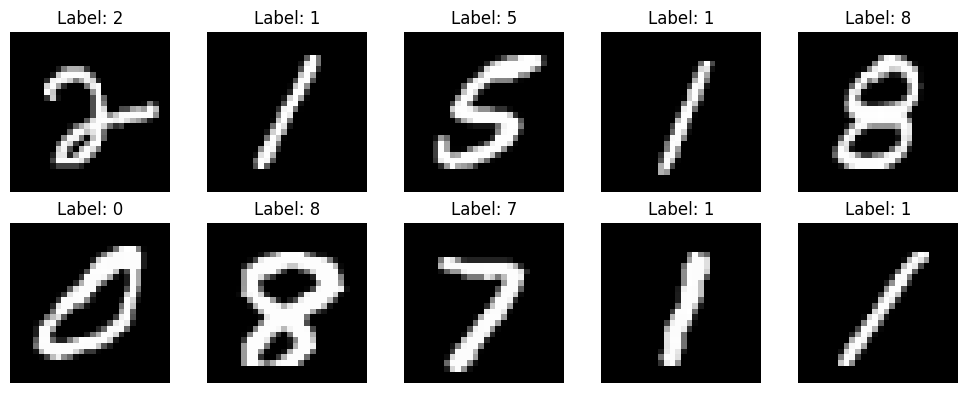

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {y_train_labels[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Exploratory data analysis

The following analysis explores the training partition. These descriptive statistics help characterize the dataset; they are not model-performance metrics.

### 6.1 Class distribution

,image_count
0,5331
1,6068
2,5362
3,5518
4,5258
5,4879
6,5326
7,5638
8,5266
9,5354


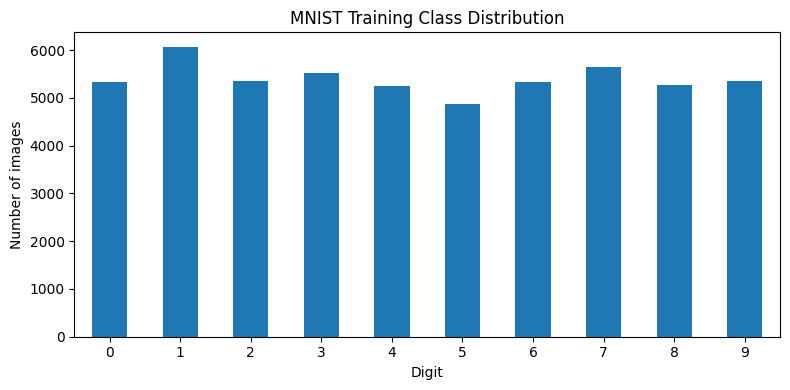

In [8]:
class_counts = pd.Series(y_train_labels).value_counts().sort_index()
display(class_counts.rename("image_count").to_frame())

ax = class_counts.plot(kind="bar", figsize=(8, 4))
ax.set_title("MNIST Training Class Distribution")
ax.set_xlabel("Digit")
ax.set_ylabel("Number of images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 6.2 Pixel intensity distribution

Minimum: 0.0000
Maximum: 1.0000
Mean:    0.1307
Std:     0.3082
Median:  0.0000


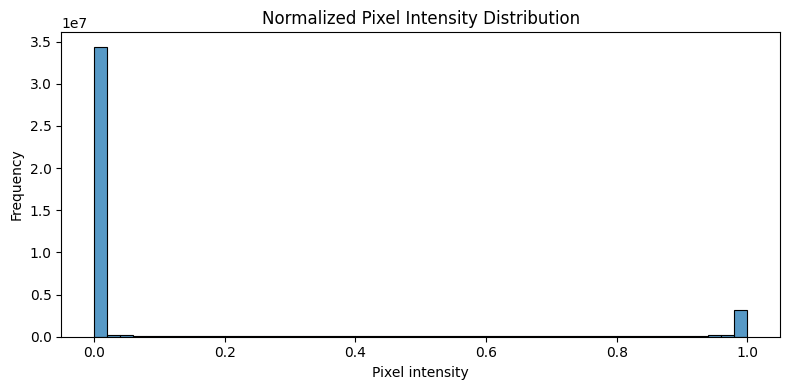

In [9]:
pixel_values = x_train.ravel()

print(f"Minimum: {pixel_values.min():.4f}")
print(f"Maximum: {pixel_values.max():.4f}")
print(f"Mean:    {pixel_values.mean():.4f}")
print(f"Std:     {pixel_values.std():.4f}")
print(f"Median:  {np.median(pixel_values):.4f}")

plt.figure(figsize=(8, 4))
sns.histplot(pixel_values, bins=50, kde=False)
plt.title("Normalized Pixel Intensity Distribution")
plt.xlabel("Pixel intensity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### 6.3 Mean, standard deviation and variance by digit

In [10]:
digit_stats = []
for digit in range(10):
    digit_pixels = x_train[y_train_labels == digit]
    digit_stats.append({
        "digit": digit,
        "mean": float(digit_pixels.mean()),
        "std": float(digit_pixels.std()),
        "variance": float(digit_pixels.var())
    })

digit_stats_df = pd.DataFrame(digit_stats).set_index("digit")
display(digit_stats_df.round(4))

,mean,std,variance
digit,,,
0,0.1734,0.3477,0.1209
1,0.0760,0.2443,0.0597
2,0.1492,0.3261,0.1064
3,0.1414,0.3178,0.1010
4,0.1214,0.2976,0.0886
5,0.1287,0.3035,0.0921
6,0.1375,0.3152,0.0993
7,0.1147,0.2918,0.0852
8,0.1504,0.3255,0.1059


### 6.4 Mean image for each digit class

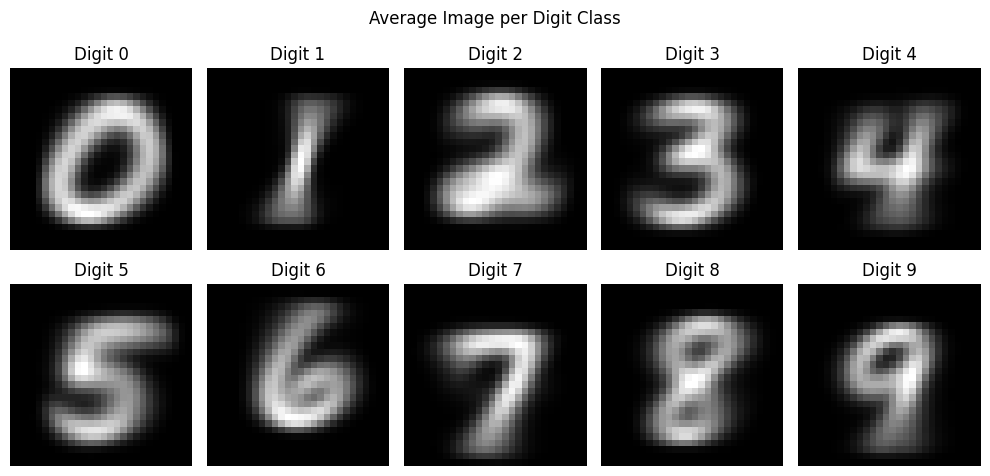

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for digit, ax in enumerate(axes.flat):
    mean_image = x_train[y_train_labels == digit].mean(axis=0).squeeze()
    ax.imshow(mean_image, cmap="gray")
    ax.set_title(f"Digit {digit}")
    ax.axis("off")
plt.suptitle("Average Image per Digit Class")
plt.tight_layout()
plt.show()

### 6.5 Non-zero pixel count per image

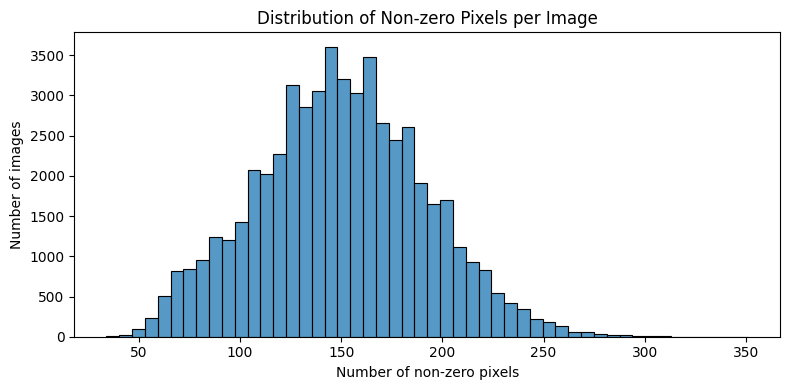

Mean non-zero pixels per image: 149.97


In [12]:
non_zero_counts = np.count_nonzero(x_train > 0, axis=(1, 2, 3))

plt.figure(figsize=(8, 4))
sns.histplot(non_zero_counts, bins=50)
plt.title("Distribution of Non-zero Pixels per Image")
plt.xlabel("Number of non-zero pixels")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

print("Mean non-zero pixels per image:", round(non_zero_counts.mean(), 2))

### 6.6 Chi-square goodness-of-fit test for class frequencies

- **Null hypothesis (H₀):** the ten digit classes occur with equal frequency in this training sample.
- **Alternative hypothesis (H₁):** the class frequencies are not all equal.

A small p-value indicates a statistically detectable departure from equal frequencies. With a large dataset, statistical significance does not necessarily imply a practically important imbalance.

In [13]:
observed = class_counts.to_numpy()
expected = np.full(10, observed.sum() / 10)

chi_stat, p_value = chisquare(f_obs=observed, f_exp=expected)

print(f"Chi-square statistic: {chi_stat:.4f}")
print(f"P-value: {p_value:.6g}")

if p_value < 0.05:
    print("Decision: Reject H0 at the 0.05 significance level.")
else:
    print("Decision: Fail to reject H0 at the 0.05 significance level.")

Chi-square statistic: 155.5833
P-value: 6.13557e-29
Decision: Reject H0 at the 0.05 significance level.


## 7. Build the CNN

In [14]:
model = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(
        filters=84,
        kernel_size=(3, 3),
        activation="relu",
        kernel_initializer="he_uniform"
    ),
    MaxPooling2D(pool_size=(3, 3)),
    Conv2D(
        filters=32,
        kernel_size=(4, 4),
        activation="relu"
    ),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(256, activation="relu"),
    Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 84)     │           840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 8, 8, 84)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 5, 5, 32)       │        43,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 2, 2, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,474 (310.45 KB)

 Trainable params: 79,474 (310.45 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Compile and train

Early stopping monitors **validation loss** and restores the best weights.

In [15]:
optimizer = SGD(learning_rate=0.01, momentum=0.9)

model.compile(
    optimizer=optimizer,
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_data=(x_val, y_val),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 22s 13ms/step - accuracy: 0.9463 - loss: 0.1706 - val_accuracy: 0.9692 - val_loss: 0.0976
Epoch 2/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - accuracy: 0.9798 - loss: 0.0635 - val_accuracy: 0.9697 - val_loss: 0.0920
Epoch 3/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 29s 17ms/step - accuracy: 0.9867 - loss: 0.0435 - val_accuracy: 0.9798 - val_loss: 0.0729
Epoch 4/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 29s 17ms/step - accuracy: 0.9900 - loss: 0.0329 - val_accuracy: 0.9812 - val_loss: 0.0694
Epoch 5/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 29s 17ms/step - accuracy: 0.9926 - loss: 0.0252 - val_accuracy: 0.9800 - val_loss: 0.0771
Epoch 6/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 29s 17ms/step - accuracy: 0.9942 - loss: 0.0201 - val_accuracy: 0.9795 - val_loss: 0.0808
Epoch 7/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 29s 17ms/step - accuracy: 0.9951 - loss: 0.0162 - val_accuracy: 0.9793 - val_loss: 0.0855


### 8.1 Training and validation curves

,accuracy,loss,val_accuracy,val_loss
2,0.986685,0.043495,0.979833,0.072889
3,0.990019,0.032912,0.981167,0.069366
4,0.992648,0.025190,0.980000,0.077092
5,0.994204,0.020081,0.979500,0.080766
6,0.995130,0.016183,0.979333,0.085480


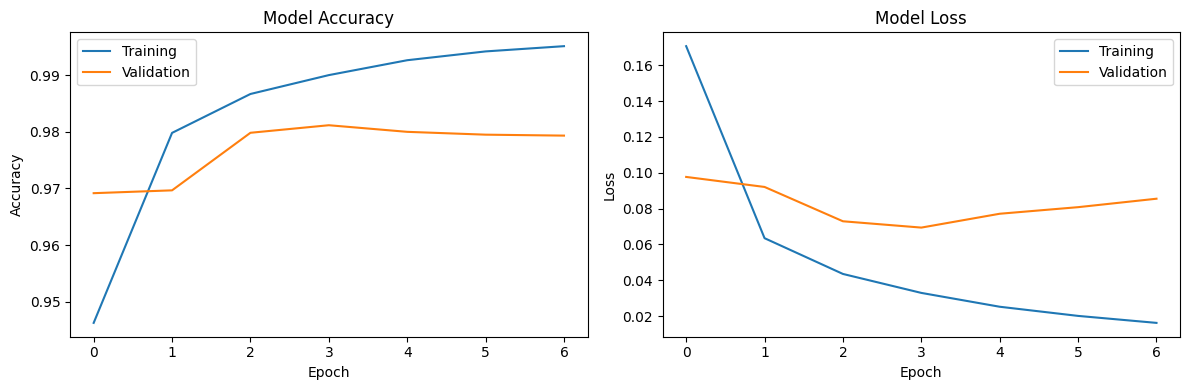

In [ ]:
history_df = pd.DataFrame(history.history)
display(history_df.tail())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Final evaluation on the test set

This is the first point at which the official MNIST test set is used for model evaluation. The result should be recorded after running the corrected notebook from top to bottom.

In [17]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4%}")

Test loss:     0.0596
Test accuracy: 98.1800%


### 9.1 Classification report

In [18]:
test_probabilities = model.predict(x_test, verbose=0)
y_pred = np.argmax(test_probabilities, axis=1)
y_true = y_test_raw

print(classification_report(y_true, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9858    0.9918    0.9888       980
           1     0.9930    0.9956    0.9943      1135
           2     0.9525    0.9913    0.9715      1032
           3     0.9979    0.9574    0.9773      1010
           4     0.9790    0.9980    0.9884       982
           5     0.9734    0.9843    0.9788       892
           6     0.9714    0.9916    0.9814       958
           7     0.9774    0.9679    0.9726      1028
           8     0.9917    0.9784    0.9850       974
           9     0.9969    0.9613    0.9788      1009

    accuracy                         0.9818     10000
   macro avg     0.9819    0.9818    0.9817     10000
weighted avg     0.9821    0.9818    0.9818     10000



### 9.2 Confusion matrix

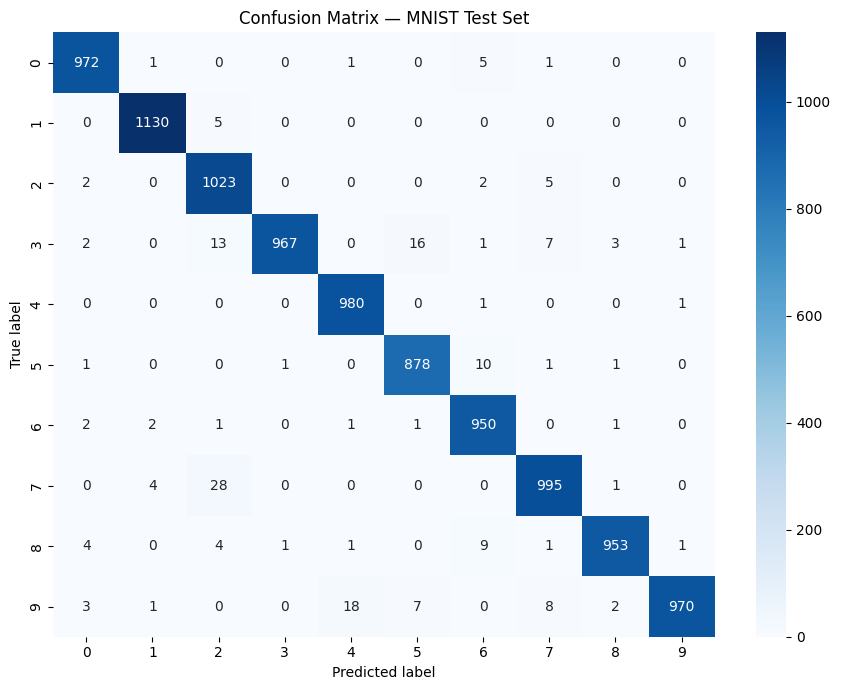

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)
plt.title("Confusion Matrix — MNIST Test Set")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

### 9.3 Inspect misclassified examples

Number of misclassified test images: 182


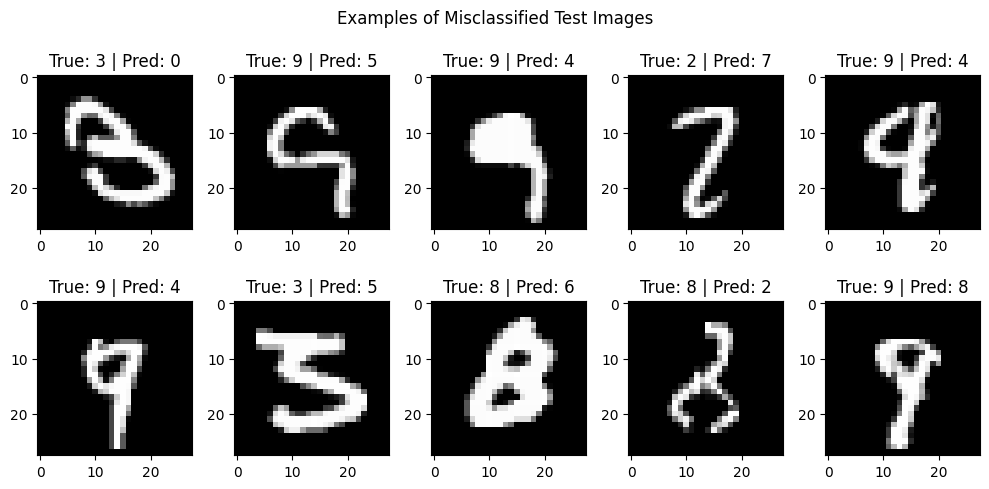

In [ ]:
misclassified_indices = np.where(y_pred != y_true)[0]
print("Number of misclassified test images:", len(misclassified_indices))

n_show = min(10, len(misclassified_indices))
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for ax in axes.flat:
    ax.axis("off")

for ax, idx in zip(axes.flat, misclassified_indices[:n_show]):
    ax.imshow(x_test[idx].squeeze(), cmap="gray")
    ax.set_title(f"True: {y_true[idx]} | Pred: {y_pred[idx]}")
    ax.axis("on")

plt.suptitle("Examples of Misclassified Test Images")
plt.tight_layout()
plt.show()

## 10. Save the trained model

The saved model can be loaded later for inference without retraining.

In [38]:
from pathlib import Path
MODEL_PATH = ROOT / "models" / "recognizer.keras"
model.save(MODEL_PATH)
print(f"Model saved to: {MODEL_PATH}")

Model saved to: ..\models\recognizer.keras


## 11. Interactive digit recognition (Google Colab)

Draw a single digit (0–9) on the canvas and select **Predict**. The canvas uses a white background and dark strokes; the preprocessing step inverts the image to match the MNIST convention of light digits on a dark background.

This interface relies on Google Colab's JavaScript callback bridge and is not intended to run unchanged in a local Jupyter Notebook.

### 11.1 Register the prediction callback

In [ ]:
from base64 import b64decode
from google.colab import output

def predict_from_canvas(image_data_url):
    header, encoded = image_data_url.split(",", 1)
    image_bytes = b64decode(encoded)

    image = Image.open(io.BytesIO(image_bytes)).convert("L")
    image = image.resize((28, 28), Image.Resampling.LANCZOS)

    image_array = np.asarray(image, dtype=np.uint8)

    # Convert dark strokes on a white canvas to MNIST-style light
    # strokes on a dark background.
    image_array = 255 - image_array
    image_array = image_array.astype("float32") / 255.0
    image_array = image_array.reshape(1, 28, 28, 1)

    if np.max(image_array) == 0:
        print("Please draw a digit before selecting Predict.")
        return

    probabilities = model.predict(image_array, verbose=0)[0]
    predicted_digit = int(np.argmax(probabilities))
    confidence = float(probabilities[predicted_digit])

    print(f"Predicted digit: {predicted_digit}")
    print(f"Model confidence: {confidence:.2%}")

output.register_callback("digit_recognizer.predict", predict_from_canvas)
print("Prediction callback registered.")

### 11.2 Drawing canvas

In [ ]:
from IPython.display import HTML, display

canvas_html = """
<div style="font-family: sans-serif; max-width: 340px;">
  <canvas id="digit-canvas" width="280" height="280"
          style="width:280px;height:280px;border:1px solid #888;
                 border-radius:8px;touch-action:none;background:white;">
  </canvas>
  <div style="margin-top:10px;display:flex;gap:8px;">
    <button id="clear-digit"
            style="padding:8px 14px;cursor:pointer;">Clear</button>
    <button id="predict-digit"
            style="padding:8px 14px;cursor:pointer;">Predict</button>
  </div>
  <p style="font-size:12px;color:#666;">
    Draw one digit (0–9), then select Predict.
  </p>
</div>

<script>
(() => {
  const canvas = document.getElementById("digit-canvas");
  const ctx = canvas.getContext("2d");
  let drawing = false;

  function resetCanvas() {
    ctx.fillStyle = "white";
    ctx.fillRect(0, 0, canvas.width, canvas.height);
  }

  function getPosition(event) {
    const rect = canvas.getBoundingClientRect();
    return {
      x: (event.clientX - rect.left) * canvas.width / rect.width,
      y: (event.clientY - rect.top) * canvas.height / rect.height
    };
  }

  canvas.addEventListener("pointerdown", (event) => {
    drawing = true;
    canvas.setPointerCapture(event.pointerId);
    const p = getPosition(event);
    ctx.beginPath();
    ctx.moveTo(p.x, p.y);
  });

  canvas.addEventListener("pointermove", (event) => {
    if (!drawing) return;
    const p = getPosition(event);
    ctx.lineWidth = 18;
    ctx.lineCap = "round";
    ctx.lineJoin = "round";
    ctx.strokeStyle = "black";
    ctx.lineTo(p.x, p.y);
    ctx.stroke();
  });

  function stopDrawing() {
    drawing = false;
    ctx.closePath();
  }

  canvas.addEventListener("pointerup", stopDrawing);
  canvas.addEventListener("pointercancel", stopDrawing);
  canvas.addEventListener("lostpointercapture", stopDrawing);

  document.getElementById("clear-digit").addEventListener("click", resetCanvas);

  document.getElementById("predict-digit").addEventListener("click", () => {
    const imageData = canvas.toDataURL("image/png");
    google.colab.kernel.invokeFunction(
      "digit_recognizer.predict",
      [imageData],
      {}
    );
  });

  resetCanvas();
})();
</script>
"""

display(HTML(canvas_html))

## 12. Notes and limitations

- The classifier recognizes one digit per drawing; multi-digit recognition is outside the current scope.
- The model is trained on MNIST, so predictions can be less reliable for handwriting styles that differ substantially from the dataset.
- The drawing canvas resizes the full canvas to 28 × 28 pixels. It does not currently perform bounding-box centering or deskewing.
- The displayed confidence is the model's Softmax probability for its selected class; it is not a guarantee that the prediction is correct.

## 13. Project references

- [MNIST handwritten digit database](http://yann.lecun.com/exdb/mnist/)
- LeCun, Y. et al. (1998). *Gradient-Based Learning Applied to Document Recognition*. Proceedings of the IEEE, 86(11), 2278–2324.